### Executable study C — explicit rule learning and masked-feature recovery

These cells execute the pinned PyClause/AnyBURL learner, source-separated masking, comparisons, symbolic proposal writer and independent recount. Running the study starts three20-second feature-learning attempts and one bounded wiring probe, then saves a new engine batch. It runs static corpus analysis only, never downloaded component code or agents. Existing graphs are evidence viewers.

The raw-wiring probe may fail under its512MB heap cap; that failure is recorded separately, not counted as zero rules. The notebook keeps all learning logs and failure artifacts. No thresholds are adjusted from results.

In [1]:
from pathlib import Path
import sys, json, contextlib
from IPython.display import display, Markdown
import pandas as pd
repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "knowledge/research/paper-6-study/relational_experiment.py").exists())
study_dir = repo / "knowledge/research/paper-6-study"
sys.path.insert(0, str(study_dir))
import relational_experiment as experiment
print("Effective frozen protocol parameters:")
display(pd.DataFrame([{"Parameter": k, "Value": str(v)} for k, v in experiment.CONFIG.items()]))


Effective frozen protocol parameters:


,Parameter,Value
0,splitSalt,paper6-relational-v1:
1,evaluationModulo,5
2,evaluationBucket,0
3,attempts,3
4,secondsPerAttempt,20
5,workers,1
6,minimumJoint,5
7,minimumSourceGroups,2
8,minimumConfidence,0.5
9,minimumCenterLift,1.05


In [2]:
# Real learning and evaluation, not a canned-output demo.
# Source-scoped facts contain no saved configuration values or credentials.
run_log = repo / "knowledge/research/paper-6-corpus/relational/notebook-execution.log"
with run_log.open("w") as log, contextlib.redirect_stdout(log), contextlib.redirect_stderr(log):
    study_result = experiment.main()
print("Completed real learning and query application; raw engine logs and a fresh batch are saved.")
display(pd.DataFrame([study_result["split"]]))


Loaded 205 rules.
Loaded 61 rules.
Loaded 205 rules.


Completed real learning and query application; raw engine logs and a fresh batch are saved.


,trainNeighborhoods,evaluationNeighborhoods,trainGraphs,evaluationGraphs,trainFamilies,evaluationFamilies,familyOverlap,cases,maskedTargetInTrainingVocabulary,unmaskedEvaluationNeighborhoods
0,7548,710,1020,87,170,30,0,402,167,308


In [3]:
# Independently reconstruct source features, masks, rule counts, metrics and proposals.
import verify_relational
verification = verify_relational.main()
import unittest
suite = unittest.TestSuite()
for pattern in ("test_relational.py", "test_relational_artifacts.py"):
    suite.addTests(unittest.defaultTestLoader.discover(str(study_dir), pattern=pattern))
report = unittest.TextTestRunner(verbosity=1).run(suite)
assert report.wasSuccessful(), "Contract or corruption test failed"
print(f"{report.testsRun} contract/corruption tests passed; {verification['verifiedCases']} masked cases independently checked.")


.

.

.

.

.

.

... (13 outputs left out)

.

.

----------------------------------------------------------------------
Ran 20 tests in 4.656s

OK


20 contract/corruption tests passed; 402 masked cases independently checked.


In [4]:
# One comparison table; abstentions stay in the all-case denominator.
names = {"anyburl":"AnyBURL rules", "association_guided":"Association shortlist", "exact_counting":"Exact-counting baseline", "center_frequency":"Center-frequency baseline"}
comparison = pd.DataFrame([{"Method": names[k], "Rules": v["rules"], "Cases": v["cases"], "Answered": v["answered"], "Recovered": v["recovered"], "Recovery / all cases": v["recoveryPerCase"], "Recovery / answered": v["recoveryPerAnswer"], "Mean family recovery": v["familyMacroRecovery"]} for k,v in study_result["metrics"].items()])
display(comparison.style.format({"Recovery / all cases":"{:.1%}","Recovery / answered":"{:.1%}","Mean family recovery":"{:.1%}"}))
print("Wire probe:", study_result["learning"]["wireProbe"]["status"], study_result["learning"]["wireProbe"].get("reason", "Completed within budget"))
print("Vocabulary coverage:", study_result["split"]["maskedTargetInTrainingVocabulary"], "/", study_result["split"]["cases"], "masked targets appear in training; all cases remain scored.")


,Method,Rules,Cases,Answered,Recovered,Recovery / all cases,Recovery / answered,Mean family recovery
0,AnyBURL rules,205,402,58,34,8.5%,58.6%,20.3%
1,Association shortlist,61,402,50,31,7.7%,62.0%,19.8%
2,Exact-counting baseline,205,402,58,34,8.5%,58.6%,20.3%
3,Center-frequency baseline,0,402,249,43,10.7%,17.3%,28.0%


Wire probe: infrastructure-failure Java heap exhausted under the fixed 512MB limit
Vocabulary coverage: 167 / 402 masked targets appear in training; all cases remain scored.


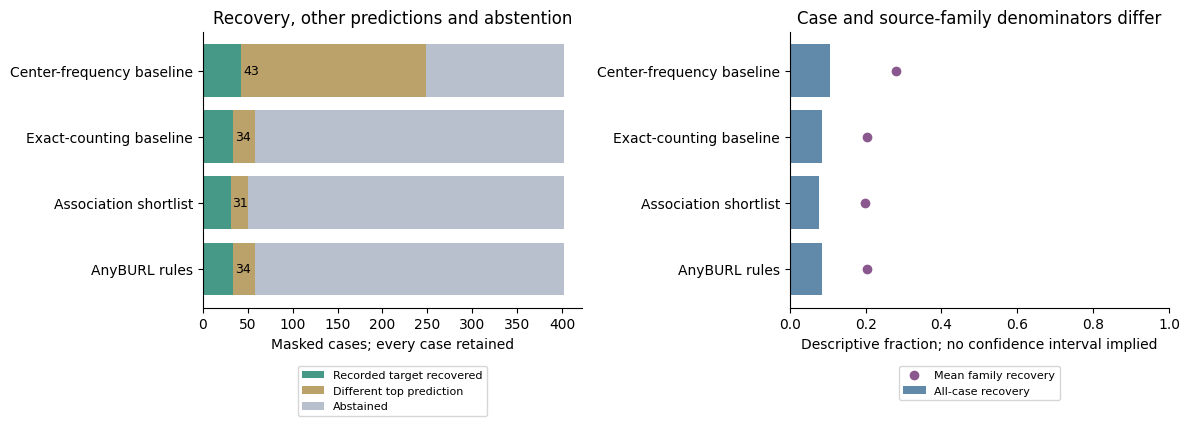

In [5]:
# Descriptive charts from the just-executed study; no independence or significance claim.
import matplotlib.pyplot as plt
import numpy as np
keys = list(names)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
labels = [names[k] for k in keys]
recovered = np.array([study_result["metrics"][k]["recovered"] for k in keys])
answered = np.array([study_result["metrics"][k]["answered"] for k in keys])
n_cases = study_result["split"]["cases"]
axes[0].barh(labels, recovered, label="Recorded target recovered", color="#479987")
axes[0].barh(labels, answered-recovered, left=recovered, label="Different top prediction", color="#bba16a")
axes[0].barh(labels, n_cases-answered, left=answered, label="Abstained", color="#b7c0cc")
for i,n in enumerate(recovered): axes[0].text(n+2,i,str(n),va="center",fontsize=9)
axes[0].set_xlabel("Masked cases; every case retained")
axes[0].set_title("Recovery, other predictions and abstention")
axes[0].legend(loc="upper center", bbox_to_anchor=(.5,-.19), fontsize=8)
axes[1].barh(labels, [study_result["metrics"][k]["recoveryPerCase"] for k in keys], color="#6189aa", label="All-case recovery")
axes[1].plot([study_result["metrics"][k]["familyMacroRecovery"] for k in keys], range(len(keys)), "o", color="#8a588e", label="Mean family recovery")
axes[1].set_xlim(0,1)
axes[1].set_xlabel("Descriptive fraction; no confidence interval implied")
axes[1].set_title("Case and source-family denominators differ")
axes[1].legend(loc="upper center", bbox_to_anchor=(.5,-.19), fontsize=8)
for ax in axes: ax.spines[["top","right"]].set_visible(False)
fig.tight_layout()
fig_dir = repo / "knowledge/research/paper-6-corpus/relational/figures"
fig_dir.mkdir(exist_ok=True)
fig.savefig(fig_dir / "recovery-comparison.png", dpi=160, bbox_inches="tight")
plt.show()


In [6]:
# Inspect explicit clauses with both training evidence and separated-source observations.
artifact = repo / "knowledge/research/paper-6-corpus/relational"
rules = json.loads((artifact / "rules.json").read_text())
cases = json.loads((artifact / "cases.json").read_text())
transactions = json.loads((repo / "knowledge/research/paper-6-corpus/patterns/transactions.json").read_text())
def connection(feature):
    center, direction, neighbor, out_port, in_port = json.loads(feature)
    return f"{neighbor}.{out_port} -> {center}.{in_port}" if direction=="in" else f"{center}.{out_port} -> {neighbor}.{in_port}"
def in_evaluation(t):
    return experiment.is_eval(transactions["families"][t["graph"]])
assessment = [t for t in transactions["transactions"] if in_evaluation(t)]
illustrations = sorted(rules,key=lambda r:(-r["jointFamilies"],-r["jointCount"],r["id"]))[:5]
rule_rows=[]
for r in illustrations:
    body=[t for t in assessment if r["body"] in t["items"]]
    joint=[t for t in body if r["head"] in t["items"]]
    rule_rows.append({"IF recorded":connection(r["body"]),"THEN candidate feature":connection(r["head"]),"Train joint/body":f"{r['jointCount']}/{r['bodyCount']}","Train families":r["jointFamilies"],"Eval joint/body":f"{len(joint)}/{len(body)}","Eval observed absences":len(body)-len(joint)})
display(pd.DataFrame(rule_rows))
print("Top five illustrations selected by training breadth; these are conditional observations, not mandatory wiring rules.")
proposals = json.loads((artifact / "proposals.json").read_text())
predictions = json.loads((artifact / "predictions.json").read_text())["anyburl"]
recovered_cases={p["case"] for p in predictions if p["recovered"]}
sample=next((p for p in proposals if p["case"] in recovered_cases and p["status"]=="proposal-only"),None)
if sample:
    print("Illustrative recovered-feature design, not an approved composite:")
    display(pd.DataFrame([{"Role":n["id"],"Type":n["descriptor"]["type"],"Version":n["descriptor"]["version"],"Training source occurrence":n["node"],"Source":n["sources"][0]["sourceUrl"]} for n in sample["nodes"]]))
    display(pd.DataFrame(sample["edges"]))
    display(pd.DataFrame(sample["requiredExposures"]))
    print("Purpose, aliasing, configured values and runtime activation remain unresolved. Full provenance and all proposals are saved as JSON.")


,IF recorded,THEN candidate feature,Train joint/body,Train families,Eval joint/body,Eval observed absences
0,ChatInput.message -> Agent.input_value,Agent.response -> ChatOutput.input_value,219/332,40,23/25,2
1,Agent.response -> ChatOutput.input_value,ChatInput.message -> Agent.input_value,219/438,40,23/35,12
2,ParseData.text -> Prompt.context,ChatInput.message -> Prompt.question,21/25,18,3/4,1
3,Prompt.prompt -> OpenAIModel.input_value,OpenAIModel.text_output -> ChatOutput.input_value,35/66,17,6/17,11
4,parser.parsed_text -> Prompt.context,ChatInput.message -> Prompt.question,36/40,15,1/3,2


Top five illustrations selected by training breadth; these are conditional observations, not mandatory wiring rules.
Illustrative recovered-feature design, not an approved composite:


,Role,Type,Version,Training source occurrence,Source
0,center,Agent,1.5.0.post1,Agent-9PDIm,https://raw.githubusercontent.com/beprith/City...
1,neighbor0,CalculatorComponent,1.8.2,CalculatorComponent-WhGEG,https://huggingface.co/spaces/raffifabiansyah/...
2,neighbor1,ChatOutput,1.3.3,ChatOutput-PlpUh,https://raw.githubusercontent.com/mzeeshanalta...


,source,target,sourcePort,targetPort,status
0,neighbor0,center,component_as_tool,tools,visible-feature role
1,center,neighbor1,response,input_value,learned-feature proposal


""


Purpose, aliasing, configured values and runtime activation remain unresolved. Full provenance and all proposals are saved as JSON.
